# Classification : état des voitures (Venant / D'occasion)

Dataset **car_data** — même démarche que le notebook *Téléphone* : exploration, préparation, Logistic Regression, Decision Tree, Random Forest, puis export du meilleur modèle pour l'application Streamlit.

**Variable cible :** `Venant_Occasion`  
**Consigne :** séparer la colonne `Adresse` (format `Quartier,Région`), garder uniquement le **quartier** et supprimer la région.

In [1]:
# Importer les packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import joblib

In [2]:
# Supprimer les warning
import warnings
warnings.filterwarnings("ignore")

### <font color = 'teal'>Importer et lire les données</font>

In [3]:
df = pd.read_csv('Car_Data 1.csv')
df.head()

,Marque,Année,Boite_Vitesse,Adresse,Prix,Venant_Occasion
0,Mitsubishi,2017,Automatique,"Liberte 6,Dakar",9750000,Venant
1,Ford,2009,Manuelle,"Yoff,Dakar",2500000,D'occasion
2,BMW,2015,Automatique,"Cité Damel,Dakar",15500000,D'occasion
3,Ford,2013,Automatique,"Almadies,Dakar",3800000,D'occasion
4,GMC,2014,Automatique,"Hlm,Dakar",7500000,Venant


In [4]:
# dimension des données
df.shape

(5507, 6)

In [5]:
# infos des données
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5507 entries, 0 to 5506
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Marque           5507 non-null   str  
 1   Année            5507 non-null   int64
 2   Boite_Vitesse    5507 non-null   str  
 3   Adresse          5507 non-null   str  
 4   Prix             5507 non-null   int64
 5   Venant_Occasion  5507 non-null   str  
dtypes: int64(2), str(4)
memory usage: 475.3 KB


### <font color = 'teal'>Traitement de l'adresse</font>

L'adresse est au format `Quartier,Région` (ex : `Almadies,Dakar`). On la sépare, on garde le quartier et on supprime la région.

In [6]:
# séparer l'adresse en quartier et région
adresse_split = df['Adresse'].str.split(',', n=1, expand=True)
df['Quartier'] = adresse_split[0].str.strip()
df['Region'] = adresse_split[1].str.strip()
df[['Adresse', 'Quartier', 'Region']].head()

,Adresse,Quartier,Region
0,"Liberte 6,Dakar",Liberte 6,Dakar
1,"Yoff,Dakar",Yoff,Dakar
2,"Cité Damel,Dakar",Cité Damel,Dakar
3,"Almadies,Dakar",Almadies,Dakar
4,"Hlm,Dakar",Hlm,Dakar


In [7]:
# répartition des régions (avant suppression)
df['Region'].value_counts()

Region
Dakar    5507
Name: count, dtype: int64

In [8]:
# on garde uniquement le quartier : suppression de l'adresse et de la région
df = df.drop(columns=['Adresse', 'Region'])
df.head()

,Marque,Année,Boite_Vitesse,Prix,Venant_Occasion,Quartier
0,Mitsubishi,2017,Automatique,9750000,Venant,Liberte 6
1,Ford,2009,Manuelle,2500000,D'occasion,Yoff
2,BMW,2015,Automatique,15500000,D'occasion,Cité Damel
3,Ford,2013,Automatique,3800000,D'occasion,Almadies
4,GMC,2014,Automatique,7500000,Venant,Hlm


In [9]:
# nombre de quartiers différents
df['Quartier'].nunique()

86

### <font color = 'teal'>Exploration et préparation des données</font>

###### <font color = 'bisque'> Sélection des variables catégorielles et quantitatives</font>

In [10]:
# sélection des variables catégorielles
cat_cols = df.select_dtypes(exclude='number')
cat_cols.head()

,Marque,Boite_Vitesse,Venant_Occasion,Quartier
0,Mitsubishi,Automatique,Venant,Liberte 6
1,Ford,Manuelle,D'occasion,Yoff
2,BMW,Automatique,D'occasion,Cité Damel
3,Ford,Automatique,D'occasion,Almadies
4,GMC,Automatique,Venant,Hlm


In [11]:
# sélection des variables quantitatives
num_cols = df.select_dtypes(include='number')
num_cols.head()

,Année,Prix
0,2017,9750000
1,2009,2500000
2,2015,15500000
3,2013,3800000
4,2014,7500000


###### <font color = 'bisque'> Exploration des variables catégorielles</font>

In [12]:
# décrire les variables catégorielles
cat_cols.describe().T

,count,unique,top,freq
Marque,5507,46,Ford,1391
Boite_Vitesse,5507,3,Automatique,4675
Venant_Occasion,5507,2,Venant,2855
Quartier,5507,86,Almadies,792


In [13]:
# répartition de chaque variable catégorielle
def countplot_func(cat_cols):
    for col in cat_cols:
        val = df[col].value_counts().head(30)  # 30 modalités les plus fréquentes
        fig = px.bar(x=val.index, y=val.values, color=val.index.astype(str), text_auto=True,
                     title=f"Répartition de : {col}")
        fig.show()

countplot_func(cat_cols)

###### <font color = 'bisque'> Exploration des variables quantitatives</font>

In [14]:
# décrire les variables quantitatives
num_cols.describe().T

,count,mean,std,min,25%,50%,75%,max
Année,5507.0,2.014508e+03,3.089839e+00,1990.0,2013.0,2015.0,2016.0,2024.0
Prix,5507.0,1.110512e+07,1.619639e+07,1.0,4600000.0,7800000.0,12500000.0,779414131.0


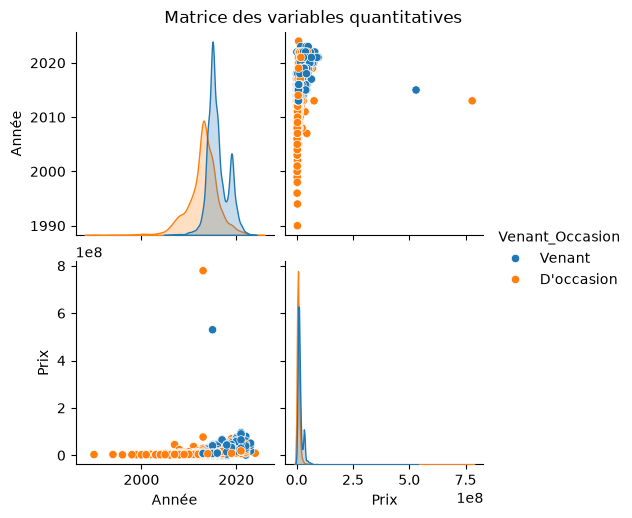

In [15]:
# pairplot des variables quantitatives
sns.pairplot(df, hue='Venant_Occasion')
plt.suptitle("Matrice des variables quantitatives", y=1.02)
plt.show()

In [16]:
# matrice de corrélation
num_cols.corr()

,Année,Prix
Année,1.000000,0.399623
Prix,0.399623,1.000000


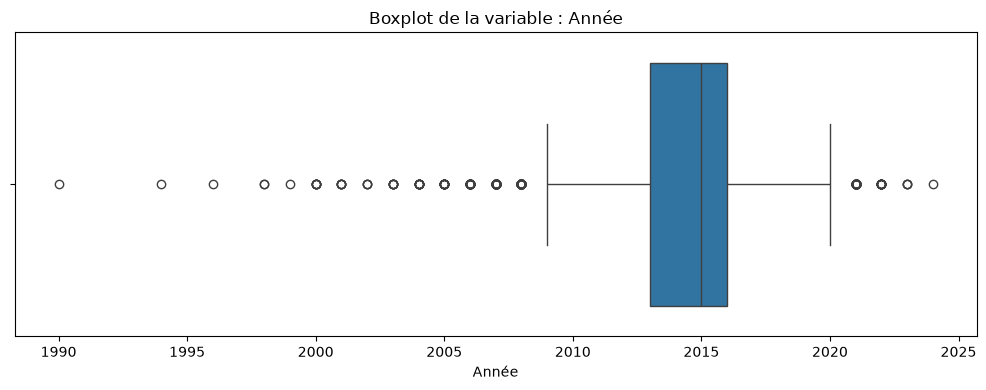

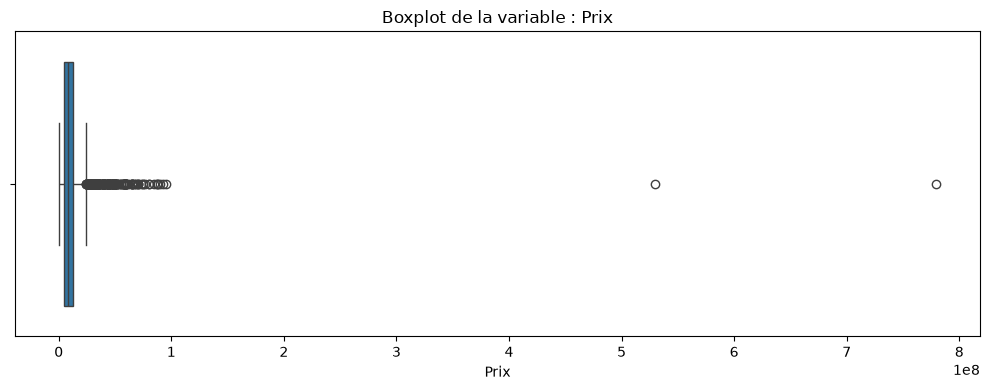

In [17]:
# fonction de visualisation des boxplots
def boxplot_func(num_cols):
    for col in num_cols:
        plt.figure(figsize=(10, 4))
        sns.boxplot(data=df, x=col)
        plt.title(f"Boxplot de la variable : {col}")
        plt.tight_layout()
        plt.show()

boxplot_func(num_cols)

###### <font color = 'bisque'> Préparation des données</font>

In [18]:
# valeurs manquantes
df.isnull().sum()

Marque             0
Année              0
Boite_Vitesse      0
Prix               0
Venant_Occasion    0
Quartier           0
dtype: int64

In [19]:
# doublons
df.duplicated().sum()

np.int64(1129)

In [20]:
# suppression des doublons
df = df.drop_duplicates().reset_index(drop=True)
df.shape

(4378, 6)

In [21]:
# Encoder les variables catégorielles (on garde chaque encodeur pour le déploiement)
from sklearn.preprocessing import LabelEncoder
encoders = {}
for col in cat_cols.columns:
    encoder = LabelEncoder()
    df[col] = encoder.fit_transform(df[col])
    encoders[col] = encoder

print(dict(zip(encoders['Venant_Occasion'].classes_, range(2))))
df.head()

{"D'occasion": 0, 'Venant': 1}


,Marque,Année,Boite_Vitesse,Prix,Venant_Occasion,Quartier
0,30,2017,0,9750000,1,49
1,13,2009,1,2500000,0,83
2,3,2015,0,15500000,0,11
3,13,2013,0,3800000,0,0
4,14,2014,0,7500000,1,38


In [22]:
from sklearn.impute import KNNImputer

# fonction d'imputation des valeurs aberrantes (méthode IQR + KNN)
def impute_func(df, col, n_neighbors=5):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    min_value = Q1 - 1.5 * IQR
    max_value = Q3 + 1.5 * IQR
    # les valeurs hors bornes deviennent des valeurs manquantes
    df.loc[(df[col] < min_value) | (df[col] > max_value), col] = np.nan
    # imputation sur les variables explicatives uniquement (pas la cible)
    features = df.columns.drop('Venant_Occasion')
    imputer = KNNImputer(n_neighbors=n_neighbors)
    df[features] = imputer.fit_transform(df[features])

In [23]:
for col in num_cols.columns:
    impute_func(df, col)

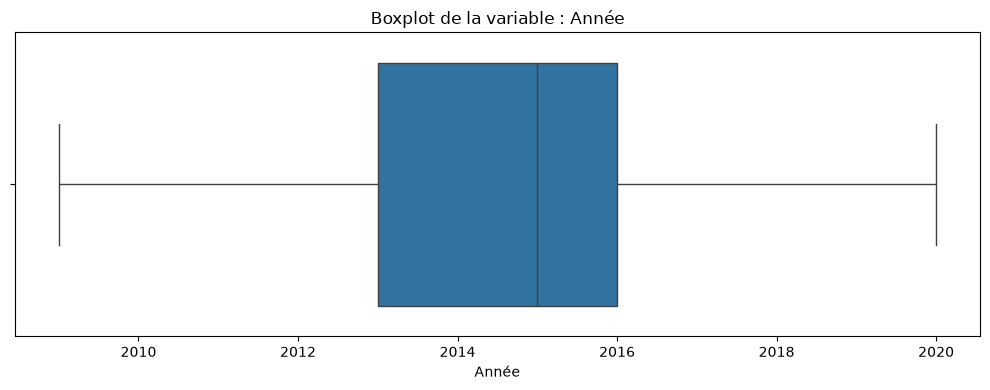

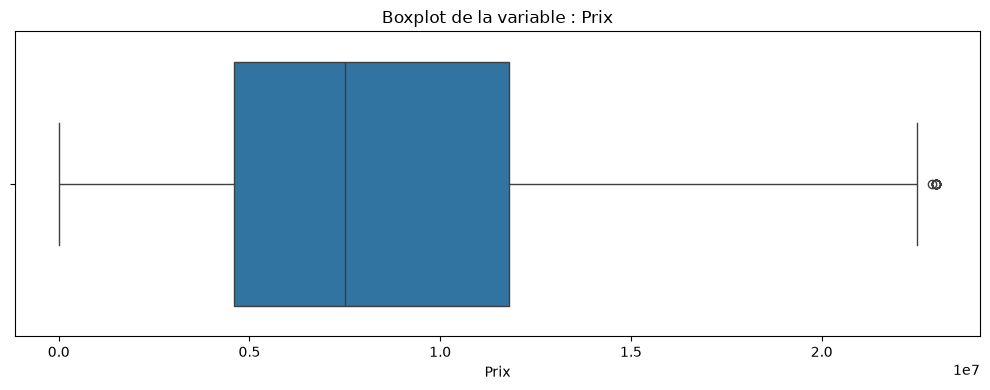

In [24]:
# revérification
boxplot_func(num_cols)

In [25]:
# séparer les variables prédicteurs (x) et la variable cible (y)
features = ['Marque', 'Année', 'Boite_Vitesse', 'Prix', 'Quartier']
x = df[features].values
y = df['Venant_Occasion'].values
x[:5], y[:5]

(array([[3.000e+01, 2.017e+03, 0.000e+00, 9.750e+06, 4.900e+01],
        [1.300e+01, 2.009e+03, 1.000e+00, 2.500e+06, 8.300e+01],
        [3.000e+00, 2.015e+03, 0.000e+00, 1.550e+07, 1.100e+01],
        [1.300e+01, 2.013e+03, 0.000e+00, 3.800e+06, 0.000e+00],
        [1.400e+01, 2.014e+03, 0.000e+00, 7.500e+06, 3.800e+01]]),
 array([1, 0, 0, 0, 1]))

In [26]:
# normaliser les données
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
x = scaler.fit_transform(x)
x[:5]

array([[0.66666667, 0.72727273, 0.        , 0.42391302, 0.57647059],
       [0.28888889, 0.        , 0.5       , 0.10869561, 0.97647059],
       [0.06666667, 0.54545455, 0.        , 0.67391303, 0.12941176],
       [0.28888889, 0.36363636, 0.        , 0.16521736, 0.        ],
       [0.31111111, 0.45454545, 0.        , 0.32608693, 0.44705882]])

In [27]:
# splitter les données : train (80%), val (10%) et test (10%)
from sklearn.model_selection import train_test_split
x_train, x_val_test, y_train, y_val_test = train_test_split(x, y, train_size=0.8, random_state=42, stratify=y)
x_val, x_test, y_val, y_test = train_test_split(x_val_test, y_val_test, train_size=0.5, random_state=42, stratify=y_val_test)
x_train.shape, x_val.shape, x_test.shape

((3502, 5), (438, 5), (438, 5))

### <font color = 'teal'>Logistic Regression</font>

###### <font color = 'bisque'> Recherche des paramètres optimaux</font>

In [28]:
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.linear_model import LogisticRegression

# validation croisée figée
cv = KFold(n_splits=5, shuffle=True, random_state=42)

params = {"C": np.logspace(-3, 3, 10), "penalty": ['l1', 'l2']}
lg = LogisticRegression(solver='liblinear')
grid = GridSearchCV(lg, params, cv=cv)
grid.fit(x_train, y_train)
grid.best_params_

{'C': np.float64(0.021544346900318832), 'penalty': 'l1'}

###### <font color = 'bisque'> Entraînement du modèle</font>

In [29]:
lg_model = LogisticRegression(solver='liblinear', **grid.best_params_)
lg_model.fit(x_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'l1'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",np.float64(0....4346900318832)
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ra

###### <font color = 'bisque'> Évaluation du modèle</font>

In [30]:
from sklearn.metrics import f1_score, accuracy_score

def evaluation(model):
    y_pred = model.predict(x_val)
    acc = accuracy_score(y_val, y_pred)
    f1 = f1_score(y_val, y_pred, average='macro')
    return acc, f1

In [31]:
acc_lg, f1_lg = evaluation(lg_model)
print(f"Accuracy: {acc_lg:.3f} et F1 Score: {f1_lg:.3f}")

Accuracy: 0.742 et F1 Score: 0.741


In [32]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

class_names = list(encoders['Venant_Occasion'].classes_)

def CM_visualisation(model_objet):
    y_pred = model_objet.predict(x_val)
    cnf_matr = confusion_matrix(y_val, y_pred, labels=[0, 1])
    disp = ConfusionMatrixDisplay(confusion_matrix=cnf_matr, display_labels=class_names)
    disp.plot()
    plt.title('Matrice de confusion')
    plt.show()

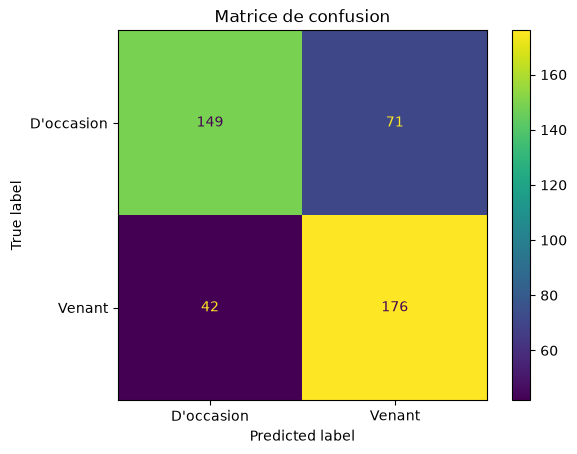

In [33]:
CM_visualisation(lg_model)

### <font color = 'teal'>Decision Tree</font>

###### <font color = 'bisque'> Recherche des paramètres optimaux</font>

In [34]:
from sklearn.tree import DecisionTreeClassifier
param__ = {'criterion': ['gini', 'entropy'], 'max_depth': np.arange(3, 15)}
dt = DecisionTreeClassifier(random_state=42)
grid__ = GridSearchCV(dt, param__, cv=cv)
grid__.fit(x_train, y_train)
grid__.best_params_

{'criterion': 'entropy', 'max_depth': np.int64(7)}

###### <font color = 'bisque'> Entraînement du modèle</font>

In [35]:
dt_model = DecisionTreeClassifier(random_state=42, **grid__.best_params_)
dt_model.fit(x_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",np.int64(7)
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number 

###### <font color = 'bisque'> Évaluation du modèle</font>

In [36]:
acc_dt, f1_dt = evaluation(dt_model)
print(f"Accuracy: {acc_dt:.3f} et F1 Score: {f1_dt:.3f}")

Accuracy: 0.763 et F1 Score: 0.761


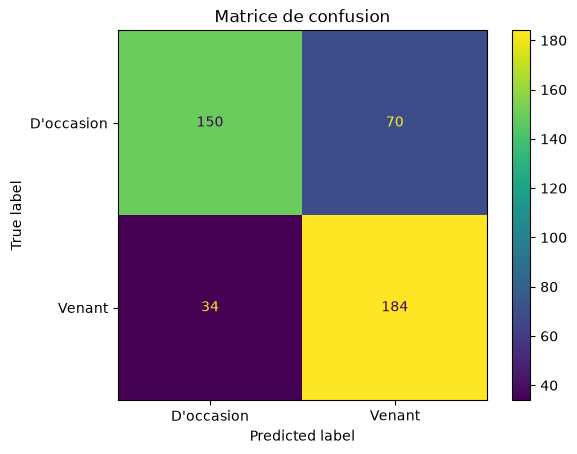

In [37]:
CM_visualisation(dt_model)

### <font color = 'teal'>Random Forest</font>

###### <font color = 'bisque'> Recherche des paramètres optimaux</font>

In [38]:
from sklearn.ensemble import RandomForestClassifier
params = {
    'n_estimators': list(np.arange(10, 100, 10)),
    'max_depth': list(np.arange(3, 15)),
    'criterion': ['gini', 'entropy']
}
rf = RandomForestClassifier(random_state=42)
grid_rf = GridSearchCV(estimator=rf, param_grid=params, cv=cv, n_jobs=-1)
grid_rf.fit(x_train, y_train)
grid_rf.best_params_

{'criterion': 'entropy',
 'max_depth': np.int64(9),
 'n_estimators': np.int64(90)}

###### <font color = 'bisque'> Entraînement du modèle</font>

In [39]:
rf_model = RandomForestClassifier(random_state=42, **grid_rf.best_params_)
rf_model.fit(x_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",np.int64(90)
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",np.int64(9)
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0


###### <font color = 'bisque'> Évaluation du modèle</font>

In [40]:
acc_rf, f1_rf = evaluation(rf_model)
print(f"Accuracy: {acc_rf:.3f} et F1 Score: {f1_rf:.3f}")

Accuracy: 0.763 et F1 Score: 0.761


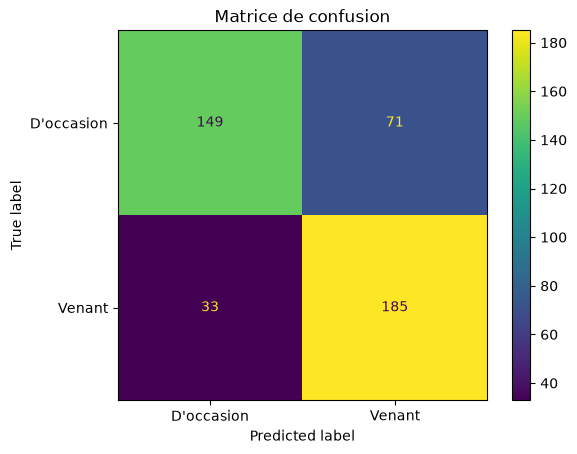

In [41]:
CM_visualisation(rf_model)

### <font color = 'teal'>Comparaison des modèles</font>

In [42]:
resultats = pd.DataFrame({
    'Modèle': ['Logistic Regression', 'Decision Tree', 'Random Forest'],
    'Accuracy': [acc_lg, acc_dt, acc_rf],
    'F1 Score': [f1_lg, f1_dt, f1_rf]
})
fig = px.bar(resultats.melt(id_vars='Modèle', var_name='Métrique', value_name='Score'),
             x='Modèle', y='Score', color='Métrique', barmode='group', text_auto='.3f',
             title='Performances sur les données de validation')
fig.show()
resultats

,Modèle,Accuracy,F1 Score
0,Logistic Regression,0.742009,0.741025
1,Decision Tree,0.762557,0.761118
2,Random Forest,0.762557,0.760942


### <font color = 'teal'>Tester le modèle le plus performant</font>

In [43]:
# choix automatique du meilleur modèle selon le F1 score
modeles = {'Logistic Regression': lg_model, 'Decision Tree': dt_model, 'Random Forest': rf_model}
best_name = resultats.sort_values('F1 Score', ascending=False).iloc[0]['Modèle']
best_model = modeles[best_name]
print('Meilleur modèle :', best_name)

y_pred_test = best_model.predict(x_test)
print(f"Accuracy test : {accuracy_score(y_test, y_pred_test):.3f}")
print(f"F1 test : {f1_score(y_test, y_pred_test, average='macro'):.3f}")

Meilleur modèle : Decision Tree
Accuracy test : 0.769
F1 test : 0.767


In [44]:
# afficher 10 prédictions sur les données test
for i in range(10):
    print(f"La voiture {i+1} est prédite {class_names[y_pred_test[i]]} ---------------- réel : {class_names[y_test[i]]}")

La voiture 1 est prédite Venant ---------------- réel : Venant
La voiture 2 est prédite Venant ---------------- réel : D'occasion
La voiture 3 est prédite D'occasion ---------------- réel : D'occasion
La voiture 4 est prédite D'occasion ---------------- réel : D'occasion
La voiture 5 est prédite Venant ---------------- réel : Venant
La voiture 6 est prédite Venant ---------------- réel : Venant
La voiture 7 est prédite D'occasion ---------------- réel : D'occasion
La voiture 8 est prédite Venant ---------------- réel : Venant
La voiture 9 est prédite D'occasion ---------------- réel : D'occasion
La voiture 10 est prédite Venant ---------------- réel : Venant


### <font color = 'teal'>Export du modèle pour Streamlit</font>

On sauvegarde le modèle, le scaler, les encodeurs et la liste des variables dans un seul fichier.

In [45]:
joblib.dump({
    'model': best_model,
    'scaler': scaler,
    'encoders': encoders,
    'features': features,
    'classes': class_names,
}, 'car_data_model.pkl')
print('Modèle sauvegardé : car_data_model.pkl')

Modèle sauvegardé : car_data_model.pkl
